# TFT - backtest

Forecasts for the trial chosen on the validation set are in `results/tft/<step>/test/trial_<n>.csv`. Columns `1`–`5` are the same seeds as in validation, and the test period is the full year from 2025-10-20 to 2026-10-18 (364 days). Each column is scored by MAE against `PL_price`, in EUR/MWh. Lower is better. The sections below read one feature set at a time, then the summary puts the three chosen trials next to each other.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

import pandas as pd

from src.config import BASE_DIR
from src.utils.evaluation import score_forecast, seed_table
from src.utils.file_io import load_final_dataset

rows = []
metric_rows = []
for step in ["d1", "d2", "d3"]:
    prices = load_final_dataset("tft", step, "test")["PL_price"]
    test_dir = BASE_DIR / "results" / "tft" / step / "test"
    for path in sorted(test_dir.glob("trial_*.csv")):
        forecast = pd.read_csv(path, index_col=0, parse_dates=True)
        number = int(path.stem.removeprefix("trial_"))
        scored = pd.DataFrame(
            {
                seed: score_forecast(
                    prices, forecast[[seed]], metrics=["MAE", "rMAE", "RMSE", "sMAPE"]
                )
                for seed in forecast.columns
            }
        )
        rows.append({"step": step, "trial": number, **scored.loc["MAE"]})
        metric_rows.append({"step": step, **scored.mean(axis=1)})

seeds = ["1", "2", "3", "4", "5"]
scores = pd.DataFrame(rows)
scores["mean"] = scores[seeds].mean(axis=1)
scores["std"] = scores[seeds].std(axis=1)


metric_mean = (
    pd.DataFrame(metric_rows)
    .set_index("step")[["MAE", "rMAE", "RMSE", "sMAPE"]]
    .sort_index()
)

## d1 — trial 114

All five seeds land between 24.3 and 25.3, so the result does not depend on which seed is drawn. The mean is 24.92, about 6 EUR/MWh above this trial's validation mean of 19.03. The spread is small (std 0.40), which means the model is stable and consistently the weakest of the three feature sets on the test year.

In [2]:
seed_table(scores, "d1")

,1,2,3,4,5
trial,,,,,
114,24.344,24.946,24.729,25.232,25.34


## d2 - trial 75

Four seeds sit between 19.1 and 19.5. Seed 1 is worse at 21.0 and pulls the mean up to 19.55 (std 0.83). The validation mean for this trial was 15.50, so the test year is about 4 EUR/MWh harder. Without seed 1 the other four average about 19.2, close to the d3 result below.

In [3]:
seed_table(scores, "d2")

,1,2,3,4,5
trial,,,,,
75,21.002,19.499,19.056,19.14,19.067


## d3 - trial 99

Seeds range from 18.4 to 20.0. The mean is 19.27 and the spread is 0.68, tighter than d2. The validation mean was 16.83, so the gap to the test set is about 2.4 EUR/MWh, smaller than for d1 and d2. Seed 3, at 18.44, is the best single run in this backtest.

In [4]:
seed_table(scores, "d3")

,1,2,3,4,5
trial,,,,,
99,19.249,19.851,18.439,20.035,18.795


## Summary

`mean` and `std` are across seeds 1–5. On the validation set d2 (15.50) beat d3 (16.83), and both beat d1 (19.03). On the test year that order changes: d3 has the lowest mean (19.27), d2 is close behind once its weak seed is taken into account, and d1 stays about 5 EUR/MWh worse. Every test mean is higher than the corresponding validation mean, which is expected for a year the model was not selected on.

In [5]:
summary = scores.set_index(["step", "trial"])[["mean", "std"]].sort_values("step")
summary.round(3)

,,mean,std
step,trial,,
d1,114,24.918,0.401
d2,75,19.553,0.830
d3,99,19.274,0.678


## Test metrics

The models were selected by minimizing `val_loss`, and that loss is MAE. The seed tables above are this same MAE on the test year. The table below compares the three steps on MAE, rMAE, RMSE and sMAPE. Each number is the mean of that metric over seeds 1–5.

MAE and RMSE are in EUR/MWh. rMAE is MAE divided by the weekly naive forecast, so a value below 1 beats it. sMAPE is the symmetric absolute percentage error from `epftoolbox`, on a scale from 0 to 2. Lower is better for all four.

d3 is ahead on MAE, rMAE and RMSE. On sMAPE, d2 and d3 are level (0.260 and 0.261). d1 is behind on every metric.

In [6]:
metric_mean.round(3)

,MAE,rMAE,RMSE,sMAPE
step,,,,
d1,24.918,0.672,39.086,0.313
d2,19.553,0.527,32.137,0.260
d3,19.274,0.520,31.342,0.261


## Error analysis

These profiles use the mean of the five seed forecasts, so the level sits a little below the mean of the seed-wise MAEs above. The error of an hour is the absolute difference from `PL_price`, and each point is the mean of those differences. d1, d2 and d3 are drawn together.

In [7]:
from src.utils.plots import plot_heatmap, plot_lines, plot_weekday

STEPS = ["d1", "d2", "d3"]
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

prices = load_final_dataset("tft", "d1", "test")["PL_price"]
errors = {}
for step in STEPS:
    path = next((BASE_DIR / "results" / "tft" / step / "test").glob("trial_*.csv"))
    forecast = pd.read_csv(path, index_col=0, parse_dates=True).mean(axis=1)
    errors[step] = (prices.reindex(forecast.index) - forecast).abs()

err = pd.DataFrame(errors)
idx = err.index
by_hour = err.groupby(idx.hour).mean()
by_dow = err.groupby(idx.dayofweek).mean()
by_dow.index = DOW
by_month = err.groupby(idx.to_period("M")).mean()
by_month.index = by_month.index.astype(str)

### Hour

Night hours 0–5 are the easiest part of the day: d2 and d3 stay near 10–11 EUR/MWh, and d1 near 13–15. The error climbs through the morning and peaks at hour 13 (d1 33.5, d2 28.6, d3 25.7), then again at hours 19–20. d1 is above the other two at every hour. d3 is lower than d2 through the middle of the day, and the two lines meet again in the evening.

In [8]:
by_hour.round(2)

,d1,d2,d3
0,13.00,10.57,9.34
1,12.96,10.31,9.49
2,13.85,10.62,10.10
3,13.97,10.60,10.05
4,14.43,10.41,10.45
5,15.24,10.48,11.09
6,19.44,13.02,13.85
7,23.15,16.73,17.43
8,23.53,18.93,19.44
9,24.40,20.43,19.84


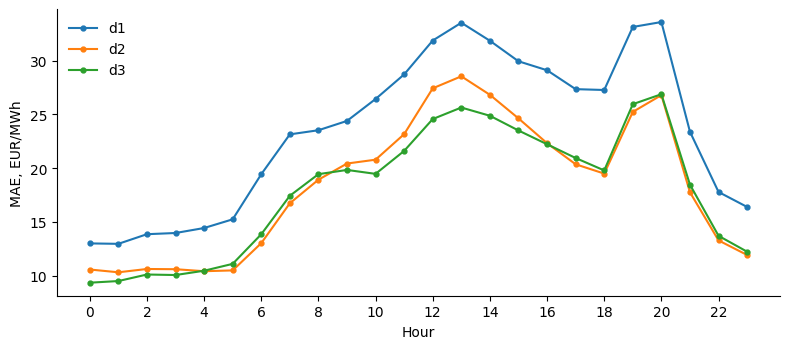

In [9]:
plot_lines(by_hour, xlabel="Hour", xticks=range(0, 24, 2))

### Weekday

Monday is the hardest weekday for every step (d1 27.5, d2 and d3 both 21.1). The error then falls toward the weekend. d3 is ahead of d2 on Saturday and Sunday (15.8 and 16.2 against 17.5 and 17.1). On Monday and Wednesday the two are level.

In [10]:
by_dow.round(2)

,d1,d2,d3
Mon,27.46,21.11,21.11
Tue,25.28,19.73,20.08
Wed,22.96,17.31,17.30
Thu,23.89,18.44,17.93
Fri,22.83,17.33,17.24
Sat,21.46,17.51,15.84
Sun,20.75,17.09,16.21


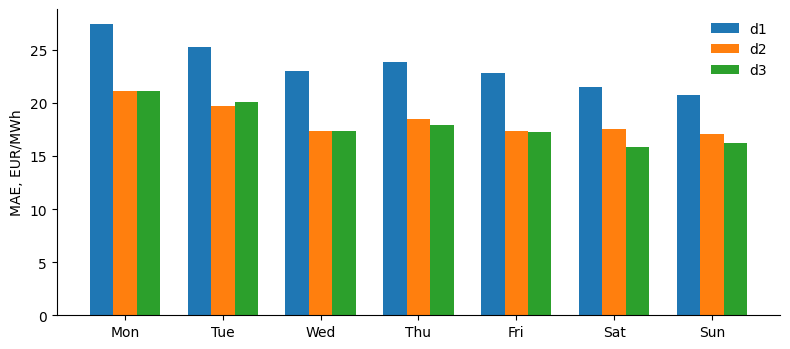

In [11]:
plot_weekday(by_dow)

### Month

Months run in chronological order. October 2025 covers the 12 days from the 20th, and October 2026 the 18 days up to the 18th. The other months are complete. September 2026 is the hardest month (d1 36.1, d2 28.6, d3 29.3), and February 2026 is the easiest. d2 and d3 stay close all year. d1's gap is already large in the first October and widest in September.

In [12]:
by_month.round(2)

,d1,d2,d3
2025-10,24.55,11.61,12.01
2025-11,19.94,14.39,14.33
2025-12,14.08,12.06,12.63
2026-01,29.87,21.26,21.72
2026-02,12.41,10.71,11.84
2026-03,20.87,16.98,15.48
2026-04,24.28,19.46,18.64
2026-05,20.89,16.74,16.05
2026-06,23.06,19.80,17.52
2026-07,22.43,19.59,18.97


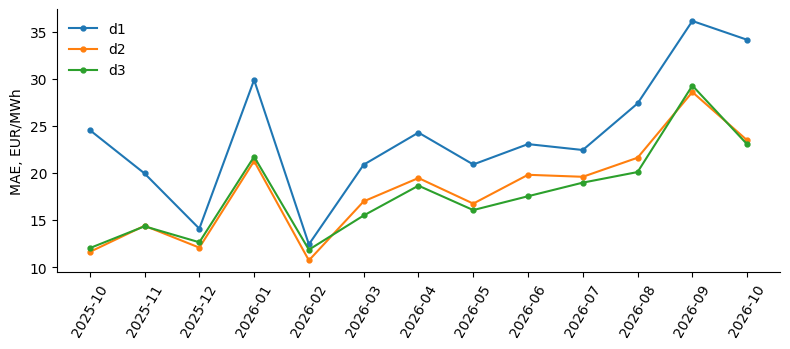

In [13]:
plot_lines(by_month, rotation=60)

### Hour by weekday

The three panels share one color scale. The daily shape is the same on every weekday: low error overnight, a midday peak, and a second peak at hours 19–20. That evening peak is strongest on Monday, where d1 reaches 47.5 EUR/MWh at hour 19. Saturday and Sunday stay darker, so the weekend is easier at every hour, not only on average.

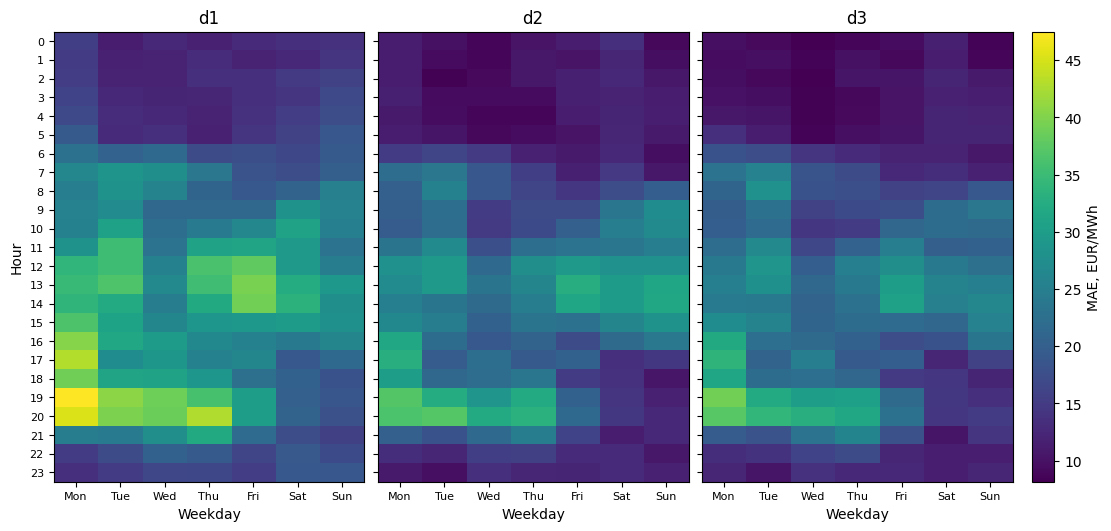

In [14]:
mats = []
for step in STEPS:
    mat = err[step].groupby([idx.hour, idx.dayofweek]).mean().unstack()
    mat.columns = DOW
    mats.append(mat)
plot_heatmap(mats, "Hour", "Weekday")

### Weekday by month

The bright cells are Mondays in January 2026 and September 2026. They stay above 39 EUR/MWh for d2 and d3, and d1 reaches 52 on the January Mondays. December 2025 and February 2026 stay dark across the whole week. The two partial Octobers are not the same month: the opening one is among the easiest for d2 and d3, and the closing one is among the hardest.

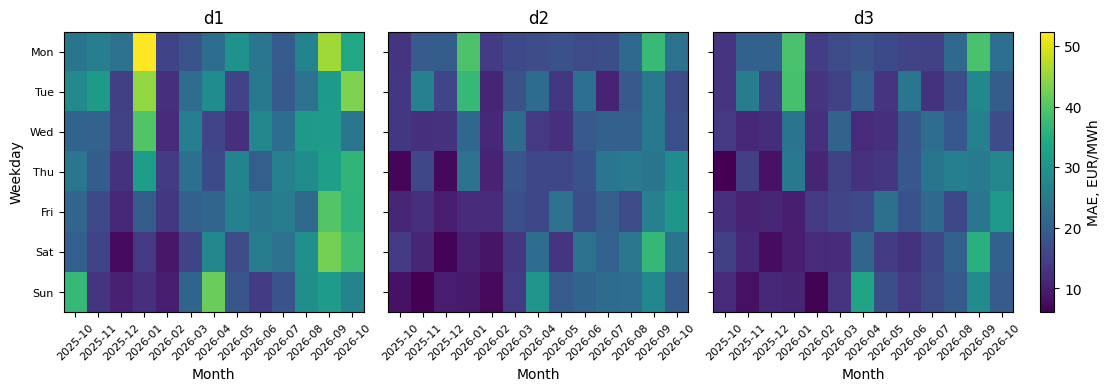

In [15]:
mats = []
for step in STEPS:
    mat = err[step].groupby([idx.dayofweek, idx.to_period("M")]).mean().unstack()
    mat.index = DOW
    mat.columns = mat.columns.astype(str)
    mats.append(mat)
plot_heatmap(mats, "Weekday", "Month")

## DM and GW tests

Each model here is the mean of its five seed forecasts, so the tests compare three forecasts. Both tests use the daily absolute errors, with all 24 hours of a day tested jointly. DM tests whether one model is more accurate than the other on average. GW is its conditional version, which also takes the previous day's loss difference into account.

Each cell of the heat map is the p-value of the one-sided test that the model on the x-axis is more accurate than the model on the y-axis. Green and yellow (p < 0.05) mean a significant difference, red (0.05–0.10) is borderline, and black (p > 0.10) means the two models cannot be told apart.

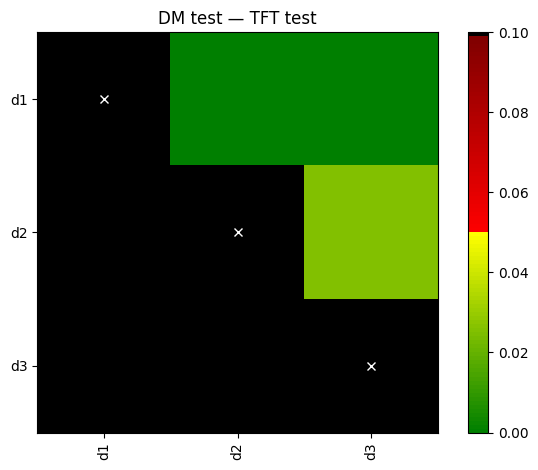

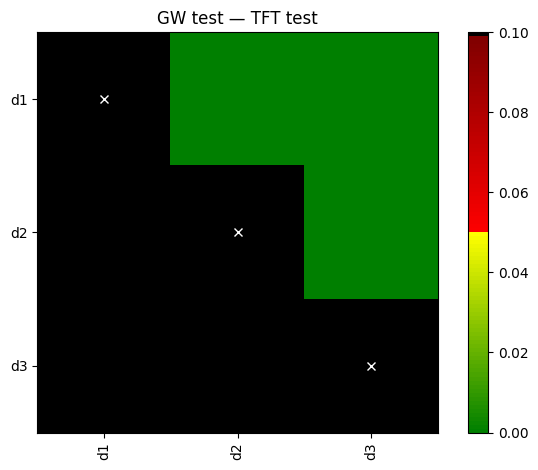

In [16]:
from epftoolbox.evaluation import plot_multivariate_DM_test, plot_multivariate_GW_test

from src.utils.evaluation import as_daily_inputs

means = {}
for step in ["d1", "d2", "d3"]:
    path = next((BASE_DIR / "results" / "tft" / step / "test").glob("trial_*.csv"))
    forecast = pd.read_csv(path, index_col=0, parse_dates=True)
    means[step] = forecast.mean(axis=1)

forecasts = pd.DataFrame(means)
prices = load_final_dataset("tft", "d1", "test")["PL_price"]
p_real, preds = as_daily_inputs(prices, forecasts)
plot_multivariate_DM_test(p_real, preds, norm=1, title="DM test — TFT test")
plot_multivariate_GW_test(p_real, preds, norm=1, title="GW test — TFT test")

## Conclusions

d1 does not carry the extra features' absence: it is stable, but its test MAE stays near 25. d2 and d3 are the real comparison. d3 wins on the mean (19.27 against 19.55), while d2's other four seeds average about 19.2, so the two sets are close and the ranking is sensitive to seed 1 of trial 75. The test year is harder than the validation window for all three, and the gap is largest for d1. The same order holds for rMAE and RMSE. On sMAPE, d2 and d3 stay level (0.260 and 0.261).

On these seed-averaged forecasts, both DM and GW find d2 and d3 significantly more accurate than d1. d3 is also significantly more accurate than d2 (DM p = 0.026, GW p = 0.0004).